Bracket found: [0, 1]


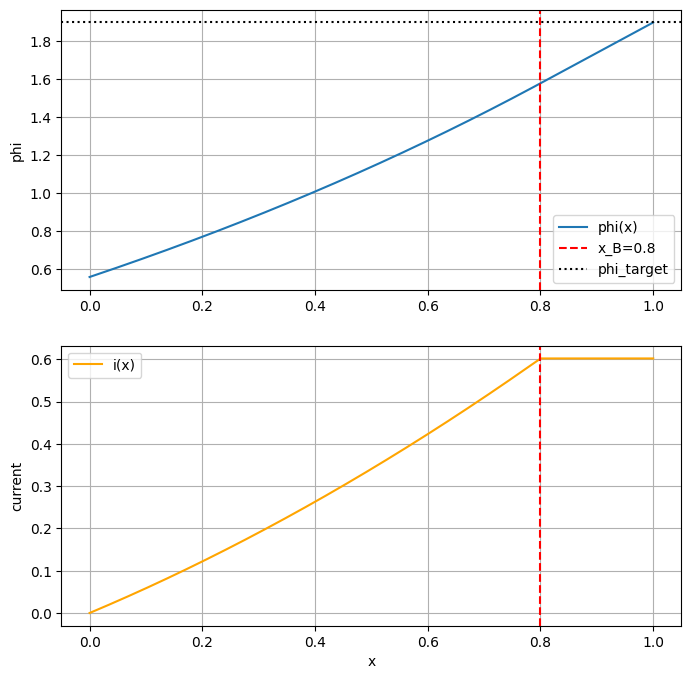

phi(0) = 0.5589
phi(1) = 1.9000
i(0)   = 0.0000
i(x_B)= 0.6023
i(1)   = 0.6023


In [1]:
#A numerical solver based on this papers: 1)Bare wire anodes for electrodynamic tethers, 2)Efficiency of Electrodynamic Tether Thrusters   
# 3) Asymptotic Solution for the Current Profile of Passive Bare Electrodynamic Tethers

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar


x_B = 0.8    #Bare length
eps_bc = 2    #Power Supply 
v_c = 0.1     #Cathode Voltage drop

phi_target = eps_bc-v_c   #For converging


def tether_ode_collect(x,y):
    phi, current = y

    dphi_dx = current+1

    if phi >= 0:
        di_dx = 0.75*np.sqrt(phi)
    else:
        di_dx = 0   

    return [dphi_dx,di_dx]



def shooting_residual(phi0_guess):

    y0 =[phi0_guess,0]   #i(0)=0

    sol = solve_ivp(tether_ode_collect,(0,x_B),y0,dense_output=True,max_step=1e-4)

    #values at x_B
       
    phi_B, i_B = sol.sol(x_B)
    phi_B = float(phi_B)
    i_B   = float(i_B) 

    phi_pred = phi_B+(i_B+1)*(1-x_B)

    return phi_pred - phi_target

#This is to find the best bracket, where the solution exists

def auto_bracket(f, start=-5, step=1, max_val=5):
    a = start
    fa = f(a)
    b = a+step

    while b <= max_val:
        fb = f(b)
        if np.sign(fa) != np.sign(fb):
            return a, b
        a,fa = b,fb
        b += step

    raise RuntimeError(
        "No valid bracket found"
    )


a,b = auto_bracket(shooting_residual)
print(f"Bracket found: [{a}, {b}]")

phi0 = root_scalar(shooting_residual, bracket=[a,b],method="brentq", xtol=1e-6).root

y0 = [phi0,0]
sol = solve_ivp(tether_ode_collect, (0, x_B), y0,dense_output=True, max_step=1e-5)

x = np.linspace(0,1,2000)
phi_profile = np.zeros_like(x)
i_profile   = np.zeros_like(x)

# Region A
maskA = x<=x_B
phi_profile[maskA], i_profile[maskA] = sol.sol(x[maskA])

# Values at x_B
phi_B, i_B = sol.sol(x_B)
phi_B = float(phi_B)
i_C   = float(i_B)

# Region B (saturated)
maskB = x>x_B
i_profile[maskB]   = i_C
phi_profile[maskB] = phi_B+(i_C + 1.0)*(x[maskB]-x_B)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8))

ax1.plot(x, phi_profile, label="phi(x)")
ax1.axvline(x_B, color="red", ls="--", label=f"x_B={x_B}")
ax1.axhline(phi_target, color="k", ls=":", label="phi_target")
ax1.set_ylabel("phi")
ax1.legend()
ax1.grid(True)

ax2.plot(x, i_profile, color="orange", label="i(x)")
ax2.axvline(x_B, color="red", ls="--")
ax2.set_xlabel("x")
ax2.set_ylabel("current")
ax2.legend()
ax2.grid(True)

plt.show()

print(f"phi(0) = {phi_profile[0]:.4f}")
print(f"phi(1) = {phi_profile[-1]:.4f}")
print(f"i(0)   = {i_profile[0]:.4f}")
print(f"i(x_B)= {i_C:.4f}")
print(f"i(1)   = {i_profile[-1]:.4f}")



In [5]:
avg_current = np.trapz(i_profile, x)
print(f"Average current over 0≤xi≤1: {avg_current:.8f}")


Average current over 0≤xi≤1: 0.34110963


/var/folders/sy/kcy_2_zx4dl93fh4mlm_07fh0000gn/T/ipykernel_34684/4110642284.py:1: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  avg_current = np.trapz(i_profile, x)


In [48]:

avg_phi = np.trapz(phi_profile, xi)
print(f"Average potential over 0≤xi≤1 = {avg_phi:.8f}")


Average potential over 0≤xi≤1 = 0.94740329


/var/folders/sy/kcy_2_zx4dl93fh4mlm_07fh0000gn/T/ipykernel_26248/2202442666.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  avg_phi = np.trapz(phi_profile, xi)


In [49]:
avg_power = avg_current*avg_phi


In [50]:
avg_power

np.float64(0.09062000773629877)

In [51]:
efficiency = avg_current/ i_profile[-1]

In [52]:
efficiency

np.float64(0.8965344268437976)

# Tether current profile numerical solver with dimensions ### 


651.3954402011389
---- Scales ----
E_m       = 2.301000e-01 V/m
L*        = 6.513954e+02 m
V* = EmL*  = 1.498861e+02 V
I* = σEmAc = 8.053500e+00 A
---- Dimensional voltages that correspond to eps_bc=2 and v_c=0.1 ----
V_bias (V)         = 5.000000e+01 V
V_cathode_drop (V) = 1.000000e+01 V
V_bias - Vc (V)    = 4.000000e+01 V
---- Dimensionless domain ----
x_B   = 1.519814e-01 (bare ends)
x_max = 1.535166e-01 (tether ends)
Bracket found: [0, 2]


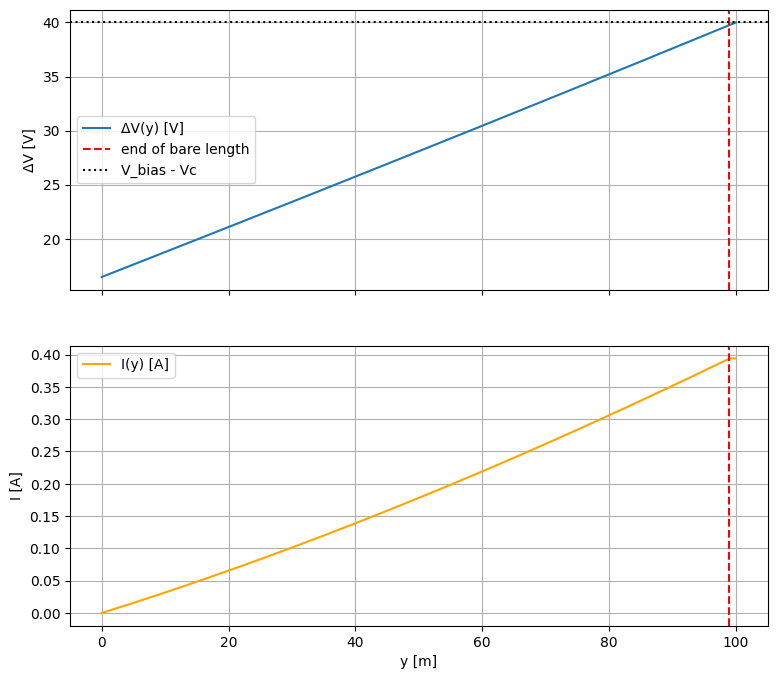


--- Dimensionless outputs (your variables) ---
phi_target = 0.266869
phi(0)     = 0.109823
phi(end)   = 0.266869
i(0)       = 0.000000
i(x_B)     = 0.048915
i(end)     = 0.048915

--- Dimensional outputs ---
ΔV(0)   = 1.646100e+01 V
ΔV(L)   = 4.000000e+01 V  (target = 4.000000e+01 V)
I(0)    = 0.000000e+00 A
I(L)    = 3.939349e-01 A


In [4]:
#A numerical solver based on this papers: 1)Bare wire anodes for electrodynamic tethers, 2)Efficiency of Electrodynamic Tether Thrusters   
# 3) Asymptotic Solution for the Current Profile of Passive Bare Electrodynamic Tethers

# Here we convert dimensional values to dimensionless values, solve it and convert back.


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar


L_total = 100.0   # [m] total tether length
L_bare  = 99.0    # [m] bare length


V_bias_volts = 50
V_cath_volts = 10


w = 0.025     
t = 40e-6     
A_c = w * t    
p_b = 2.0 * (w + t)  

# Al conductivity 
sigma = 3.5e7  

# Considering always B field perpendicular to V
v_orb  = 7.67e3   
B_perp = 30e-6    
E_m = v_orb * B_perp  

# Plasma density at ~400 km
N_inf = 5.0e11  


e  = 1.602176634e-19
m_e = 9.10938356e-31

L_star = (2.0*A_c/p_b)**(2.0/3.0) * (9.0*np.pi**2*m_e*sigma**2*E_m/(128.0*e**3*N_inf**2))**(1.0/3.0)

V_star = E_m * L_star               
I_star = sigma * E_m * A_c  

x_eps_bc = V_bias_volts/V_star  
x_v_c    = V_cath_volts/V_star   




#L_star = 570

print(L_star)



      


# Dimensionless target boundary condition 
phi_target = x_eps_bc - x_v_c


# -------------------------
x_max = L_total / L_star
x_B   = L_bare  / L_star

print("---- Scales ----")
print(f"E_m       = {E_m:.6e} V/m")
print(f"L*        = {L_star:.6e} m")
print(f"V* = EmL*  = {V_star:.6e} V")
print(f"I* = σEmAc = {I_star:.6e} A")
print("---- Dimensional voltages that correspond to eps_bc=2 and v_c=0.1 ----")
print(f"V_bias (V)         = {V_bias_volts:.6e} V")
print(f"V_cathode_drop (V) = {V_cath_volts:.6e} V")
print(f"V_bias - Vc (V)    = {(V_bias_volts - V_cath_volts):.6e} V")
print("---- Dimensionless domain ----")
print(f"x_B   = {x_B:.6e} (bare ends)")
print(f"x_max = {x_max:.6e} (tether ends)")


def tether_ode_collect(x,y):
    phi, current = y

  
    dphi_dx = current + 1.0

    if phi >= 0:
        di_dx = 0.75 * np.sqrt(phi)
    else:
        di_dx = 0.0

    return [dphi_dx, di_dx]

# Shooting residual 
def shooting_residual(phi0_guess):
    y0 = [phi0_guess, 0.0]  # i(0)=0

    sol = solve_ivp(
        tether_ode_collect,
        (0.0, x_B),
        y0,
        dense_output=True,
        max_step=max(1e-4, x_B/20000)  
    )

    phi_B, i_B = sol.sol(x_B)
    phi_B = float(phi_B)
    i_B   = float(i_B)

    # insulated region: i constant; phi increases with slope (i+1)
    phi_pred = phi_B + (i_B + 1.0) * (x_max - x_B)

    return phi_pred - phi_target


# to find the best bracket for solving
def auto_bracket(f, start=-20.0, step=2.0, max_val=200.0):
    a = start
    fa = f(a)
    b = a + step
    while b <= max_val:
        fb = f(b)
        if np.sign(fa) != np.sign(fb):
            return a, b
        a, fa = b, fb
        b += step
    raise RuntimeError("No valid bracket found. Increase max_val or change start/step.")

# Solve for phi(0)
a, b = auto_bracket(shooting_residual, start=-20, step=2, max_val=300)
print(f"Bracket found: [{a}, {b}]")

phi0 = root_scalar(shooting_residual, bracket=[a, b], method="brentq", xtol=1e-8).root


sol = solve_ivp(
    tether_ode_collect,
    (0.0, x_B),
    [phi0, 0.0],
    dense_output=True,
    max_step=max(1e-5, x_B/50000)
)

# Build full profiles in x = y/L*
x = np.linspace(0.0, x_max, 5000)
phi_profile = np.zeros_like(x)
i_profile   = np.zeros_like(x)

# Region A (bare)
maskA = x <= x_B
phi_profile[maskA], i_profile[maskA] = sol.sol(x[maskA])

# Values at x_B
phi_B, i_B = sol.sol(x_B)
phi_B = float(phi_B)
i_C   = float(i_B)

# Region B (insulated)
maskB = x > x_B
i_profile[maskB]   = i_C
phi_profile[maskB] = phi_B + (i_C + 1.0) * (x[maskB] - x_B)


# Convert to dimensional units

y_m = x * L_star                
DeltaV_V = phi_profile * V_star  
I_A = i_profile * I_star         

# Plots 

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

ax1.plot(y_m, DeltaV_V, label="ΔV(y) [V]")
ax1.axvline(L_bare, color="red", ls="--", label="end of bare length")
ax1.axhline(V_bias_volts - V_cath_volts, color="k", ls=":", label="V_bias - Vc")
ax1.set_ylabel("ΔV [V]")
ax1.grid(True)
ax1.legend()

ax2.plot(y_m, I_A, color="orange", label="I(y) [A]")
ax2.axvline(L_bare, color="red", ls="--")
ax2.set_xlabel("y [m]")
ax2.set_ylabel("I [A]")
ax2.grid(True)
ax2.legend()

plt.show()

print("\n--- Dimensionless outputs (your variables) ---")
print(f"phi_target = {phi_target:.6f}")
print(f"phi(0)     = {phi_profile[0]:.6f}")
print(f"phi(end)   = {phi_profile[-1]:.6f}")
print(f"i(0)       = {i_profile[0]:.6f}")
print(f"i(x_B)     = {i_C:.6f}")
print(f"i(end)     = {i_profile[-1]:.6f}")

print("\n--- Dimensional outputs ---")
print(f"ΔV(0)   = {DeltaV_V[0]:.6e} V")
print(f"ΔV(L)   = {DeltaV_V[-1]:.6e} V  (target = {(V_bias_volts - V_cath_volts):.6e} V)")
print(f"I(0)    = {I_A[0]:.6e} A")
print(f"I(L)    = {I_A[-1]:.6e} A")


# Generating Plots for Iavg and Favg based on V_bias, Length, Width. Power contours overlayed.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar


w = 0.005 # width
t = 40e-6 # thickness
A_c = w * t
p_b = 2.0 * (w + t)

sigma = 3.5e7  # Al

v_orb  = 7.67e3
B_perp = 30e-6
E_m = v_orb * B_perp  

# Plasma density
N_inf = 5.0e11  # 1/m^3

# Constants
e   = 1.602176634e-19
m_e = 9.10938356e-31

# Cathode drop 
V_cath_volts = 10.0  # V

# Characteristic length L* 
L_star = (2.0 * A_c / p_b) ** (2.0 / 3.0) * (
    (9.0 * np.pi**2 * m_e * sigma**2 * E_m) / (128.0 * e**3 * N_inf**2)
) ** (1.0 / 3.0)


V_star = E_m * L_star
I_star = sigma * E_m * A_c

print("---- Scales ----")
print(f"E_m       = {E_m:.6e} V/m")
print(f"L*        = {L_star:.6e} m")
print(f"V* = EmL*  = {V_star:.6e} V")
print(f"I* = σEmAc = {I_star:.6e} A")


def tether_ode_collect(x, y):
    phi, current = y
    dphi_dx = current + 1.0
    if phi >= 0:
        di_dx = 0.75 * np.sqrt(phi)
    else:
        di_dx = 0.0
    return [dphi_dx, di_dx]


def auto_bracket(f, start=-50.0, step=5.0, max_val=200.0):
    a = start
    fa = f(a)
    b = a + step
    while b <= max_val:
        fb = f(b)
        if np.sign(fa) != np.sign(fb):
            return a, b
        a, fa = b, fb
        b += step
    raise RuntimeError("No valid bracket found. Expand range/step.")


# SWEEP RANGES

L_list = np.linspace(20, 1000, 50)      # [m]
Vbias_list = np.linspace(15, 500, 50)   # [V]

Iavg_map = np.full((len(Vbias_list), len(L_list)), np.nan)  
P_map    = np.full((len(Vbias_list), len(L_list)), np.nan)  
F_map    = np.full((len(Vbias_list), len(L_list)), np.nan)  

# power contour at P_special
P_special = [15.0]  



for i, V_bias in enumerate(Vbias_list):
    for j, L_total in enumerate(L_list):

        #L_bare = 0.99 * L_total
        L_bare = L_total

        # Dimensionless bias and cathode drop
        eps_bc = V_bias / V_star
        v_c    = V_cath_volts / V_star
        phi_target = eps_bc - v_c

        # Dimensionless lengths
        x_max = L_total / L_star
        x_B   = L_bare  / L_star

        try:
            def shooting_residual(phi0_guess):
                sol = solve_ivp(
                    tether_ode_collect,
                    (0.0, x_B),
                    [phi0_guess, 0.0],
                    dense_output=True,
                    max_step=max(x_B/2000, 1e-6)
                )
                phi_B, i_B = sol.sol(x_B)
                phi_pred = float(phi_B) + (float(i_B) + 1.0) * (x_max - x_B)
                return phi_pred - phi_target

            a_br, b_br = auto_bracket(shooting_residual, start=-50, step=5, max_val=200)
            phi0 = root_scalar(shooting_residual, bracket=[a_br, b_br], method="brentq").root

            sol = solve_ivp(
                tether_ode_collect,
                (0.0, x_B),
                [phi0, 0.0],
                dense_output=True,
                max_step=max(x_B/2000, 1e-6)
            )

            # Build profile
            x = np.linspace(0.0, x_max, 2000)
            y = x * L_star  # meters

            i_prof = np.zeros_like(x)

            maskA = x <= x_B
            _, i_prof[maskA] = sol.sol(x[maskA])

            _, i_B = sol.sol(x_B)
            i_B = float(i_B)

            maskB = x > x_B
            i_prof[maskB] = i_B

            # Dimensional current profile
            I_A = i_prof * I_star

            # Average current
            I_avg = np.trapz(I_A, y) / L_total   # A
            Iavg_map[i, j] = I_avg

            # Power
            P_map[i, j] = I_avg * V_bias         # W

            # Force: 
            F_map[i, j] = I_avg * L_total * B_perp  # N

        except Exception:
            # leave NaNs
            pass

# -------------------------
# FIGURE 1: Iavg MAP (COLOR) + POWER CONTOURS + 15 W CONTOUR
# -------------------------
fig1, ax1 = plt.subplots(figsize=(10, 6))

im1 = ax1.imshow(
    Iavg_map,
    extent=[L_list[0], L_list[-1], Vbias_list[0], Vbias_list[-1]],
    origin="lower",
    aspect="auto",
    cmap="viridis"
)

cbar1 = fig1.colorbar(im1, ax=ax1)
cbar1.set_label("Average tether current ⟨I⟩ [A]")

ax1.set_xlabel("Tether length [m]")
ax1.set_ylabel("Bias voltage [V]")
ax1.set_title("EDT ⟨I⟩ Map with Power Contours")

# power contours
CS1 = ax1.contour(
    L_list,
    Vbias_list,
    P_map,
    colors="white",
    linewidths=1.0
)
ax1.clabel(CS1, inline=True, fontsize=9, fmt="%.1f W")

# p_special contour
CS1_15 = ax1.contour(
    L_list,
    Vbias_list,
    P_map,
    levels=P_special,
    colors="red",
    linewidths=2.5
)
ax1.clabel(CS1_15, inline=True, fontsize=10, fmt="15 W")


fig1.savefig("Iavg_map_with_power_contours_0.5cm.png", dpi=300, bbox_inches="tight")
plt.show()

# -------------------------
# FIGURE 2: FORCE MAP (COLOR) + POWER CONTOURS + 15 W CONTOUR
# -------------------------
fig2, ax2 = plt.subplots(figsize=(10, 6))

im2 = ax2.imshow(
    F_map,
    extent=[L_list[0], L_list[-1], Vbias_list[0], Vbias_list[-1]],
    origin="lower",
    aspect="auto",
    cmap="viridis"
)

cbar2 = fig2.colorbar(im2, ax=ax2)
cbar2.set_label("Average Lorentz force ⟨F⟩ = ⟨I⟩ L B [N]")

ax2.set_xlabel("Tether length [m]")
ax2.set_ylabel("Bias voltage [V]")
ax2.set_title("EDT ⟨F⟩ Map with Power Contours")

# power contours
CS2 = ax2.contour(
    L_list,
    Vbias_list,
    P_map,
    colors="white",
    linewidths=1.0
)
ax2.clabel(CS2, inline=True, fontsize=9, fmt="%.1f W")

# p_special contour
CS2_15 = ax2.contour(
    L_list,
    Vbias_list,
    P_map,
    levels=P_special,
    colors="red",
    linewidths=2.5
)
ax2.clabel(CS2_15, inline=True, fontsize=10, fmt="15 W")


fig2.savefig("Force_map_with_power_contours_0.5cm.png", dpi=300, bbox_inches="tight")
plt.show()


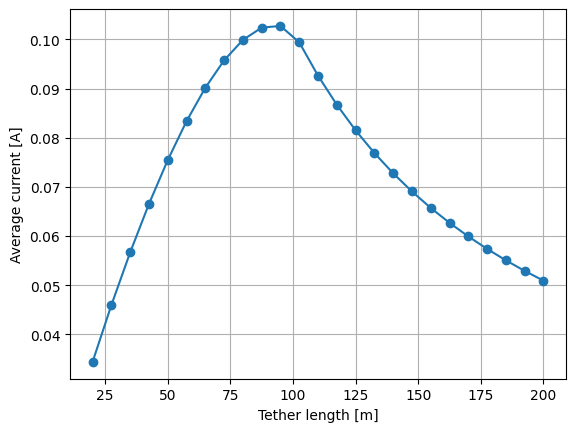

In [44]:
plt.figure()
plt.plot(L_list, Iavg_map[10, :], marker='o')
plt.xlabel("Tether length [m]")
plt.ylabel("Average current [A]")
plt.grid(True)
plt.show()
